# code_010 · Optimization and numerical computation

**Book:** Chapter 2, section 2.4. **Scope:** a mathematics laboratory, with exact toy models and generated data. This is not a field-validation study or an exhaustive estimator-constructor lab. All imports, inputs and helpers are contained here.

Use the [quickstart](../README.md) and [pinned environment](../requirements-lock.txt), then restart and run all cells. The reference environment is CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1 and Matplotlib 3.11.0, macOS ARM64 CPU. No data downloads, API keys, GPU or project imports are needed. Allow a minute for execution and 30–60 minutes for predictions and exercises. Actual runtime appears at the end and in [execution evidence](../CHAPTER_02_EXECUTION.md).

Read each prediction before revealing output. Controls here are coordinate choices, numerical-method settings and stated system/data assumptions; they are not collectively model hyperparameters. These constructed mechanism checks do not need a supervised train/test split. A later fitted predictive pipeline must learn scales and representations on training data only. See the [concept-to-code guide](../CHAPTER_02_GUIDE.md) and [stable code directory](../CODE_EXAMPLES.md#code_010).


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter(); SEED=202
rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine())
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64


<a id="quadratic"></a>
## Same objective, different update geometry

Minimize L=(theta1²+100 theta2²)/2 from (2,1), with dimensionless coordinates. For ordinary fixed-step descent each eigenmode is multiplied by 1-eta*lambda. Here convergence from every start requires 0<eta<0.02. The scaled update uses exact diagonal inverse curvature; this is mechanism isolation, not a fair general optimizer benchmark. The coordinate map z=(theta1,10 theta2) gives the same objective with equal curvatures.

**Predict:** why does eta=0.019 zigzag while eta=0.021 diverges? Which mode limits stability and which limits speed?


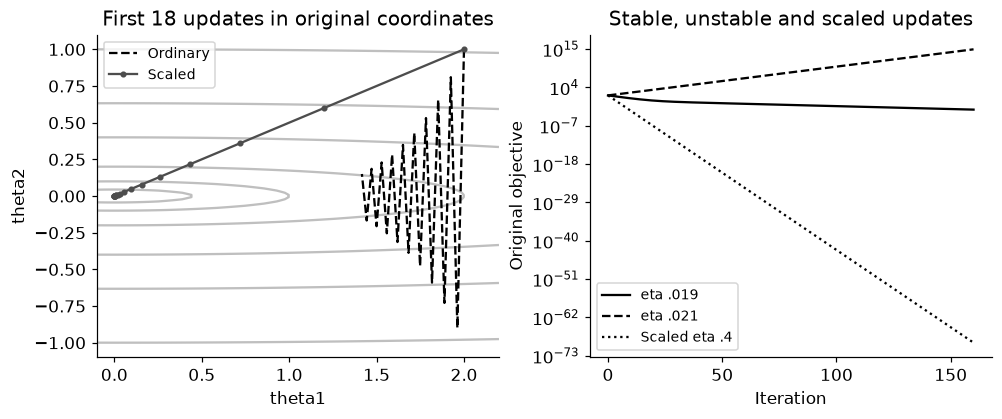

In [2]:
curvature=np.array([1.,100.]);start=np.array([2.,1.])
def loss(theta):return .5*np.sum(curvature*np.asarray(theta)**2,axis=-1)
def descent(rate,preconditioner,steps=160,lower=None):
 path=[start.copy()]
 for _ in range(steps):
  candidate=path[-1]-rate*preconditioner*curvature*path[-1]
  if lower is not None:candidate=np.maximum(candidate,lower)
  path.append(candidate)
 return np.array(path)
ordinary=descent(.019,np.ones(2));unstable=descent(.021,np.ones(2));scaled=descent(.4,1/curvature)
assert loss(ordinary[-1])<loss(start) and loss(unstable[-1])>1e10
assert loss(scaled[-1])<1e-50
assert np.allclose(ordinary[1],(1-.019*curvature)*start)
fig,axes=plt.subplots(1,2,figsize=(9,3.7));xx,yy=np.meshgrid(np.linspace(-.1,2.2,150),np.linspace(-1.1,1.1,150))
axes[0].contour(xx,yy,.5*(xx**2+100*yy**2),levels=[.1,.5,2,8,20,50],colors='.75')
axes[0].plot(*ordinary[:19].T,'k--',label='Ordinary');axes[0].plot(*scaled[:19].T,'o-',color='.3',ms=3,label='Scaled')
axes[0].set(xlabel='theta1',ylabel='theta2',title='First 18 updates in original coordinates');axes[0].legend(fontsize=9)
for path,style,label in [(ordinary,'-','eta .019'),(unstable,'--','eta .021'),(scaled,':','Scaled eta .4')]:axes[1].semilogy(loss(path),color='black',ls=style,label=label)
axes[1].set(xlabel='Iteration',ylabel='Original objective',title='Stable, unstable and scaled updates');axes[1].legend(fontsize=9);plt.show()
RESULTS['ordinary_final_loss']=float(loss(ordinary[-1]));RESULTS['unstable_final_loss']=float(loss(unstable[-1]));RESULTS['scaled_final_loss']=float(loss(scaled[-1]))


<a id="constraints"></a>
## A nonzero gradient at a constrained optimum

Require theta1>=0.2 while theta2 is unrestricted. Project each scaled update back into the box. The minimizer is (0.2,0) with loss 0.02. Its unconstrained gradient is nonzero; the projected update is zero because the proposed reduction of theta1 is infeasible. Constraints change the problem, whereas coordinate scaling preserved the problem.

**Predict:** does stopping only when the ordinary gradient is tiny make sense at this constrained optimum?


In [3]:
lower=np.array([.2,-np.inf]);constrained=descent(.4,1/curvature,lower=lower)
last=constrained[-1];gradient=curvature*last
projected_update=last-np.maximum(last-.4*gradient/curvature,lower)
assert np.all(constrained[:,0]>=.2) and np.allclose(last,[.2,0],atol=1e-15)
assert np.linalg.norm(gradient)>.1 and np.linalg.norm(projected_update)<1e-15
print('Feasible minimizer:',last,'loss:',loss(last),'unconstrained gradient:',gradient)
RESULTS['constrained_final_loss']=float(loss(last));RESULTS['constrained_gradient_norm']=float(np.linalg.norm(gradient))


Feasible minimizer: [2.0000000e-01 3.1930084e-36] loss: 0.020000000000000004 unconstrained gradient: [2.0000000e-01 3.1930084e-34]


<a id="precision"></a>
## Precision is not observation noise

The expression (a+1)-a equals one over real numbers. At a=1e8, float32 cannot represent that addition, while float64 can. Casting to float64 after the small increment has already been lost cannot recover it. This isolated example does not establish that every float32 model fails, or that precision fixes ill-identified coefficients.

**Predict:** does changing dtype after addition repair the zero? What if the true measurement uncertainty is 1000 rather than one?


In [4]:
precision={}
for dtype in [np.float32,np.float64]:
 a=dtype(1e8);answer=(a+dtype(1))-a
 precision[dtype.__name__]=float(answer)
print(precision)
assert precision=={'float32':0.,'float64':1.}
RESULTS['cancellation']=precision


{'float32': 0.0, 'float64': 1.0}


<a id="linear-solves"></a>
## Small residual, sensitive solution

Solve A=diag(1,1e-6) first for b=(1,1e-6), then for a right-hand side perturbed by (0,1e-6). Both solves have tiny residuals but solutions differ markedly. A direct solver avoids explicitly forming an inverse; it cannot remove uncertainty amplified by the problem.

For full-column-rank X, cond(X.T@X)=cond(X)² in the two-norm in exact arithmetic. The example compares direct least squares with normal equations at moderate conditioning and prints actual differences rather than asserting that one always wins every tiny case. At very high condition numbers numerical rank and roundoff require explicit interpretation.


In [5]:
A=np.diag([1.,1e-6]);rhs=np.array([1.,1e-6]);delta=np.array([0.,1e-6])
solution=np.linalg.solve(A,rhs);changed=np.linalg.solve(A,rhs+delta)
assert np.allclose(solution,[1,1]) and np.allclose(changed,[1,2])
assert np.linalg.norm(A@changed-(rhs+delta))<1e-14
print('relative data change:',np.linalg.norm(delta)/np.linalg.norm(rhs),'solution change:',np.linalg.norm(changed-solution))
x=np.linspace(-1,1,80);z=np.cos(np.arange(80));z-=x*(x@z)/(x@x);z/=np.linalg.norm(z)
X=np.column_stack([x,x+.01*z]);target=X@np.array([1.,2.])+rng.normal(0,1e-5,len(x))
least_squares,resid,rank,singular=np.linalg.lstsq(X,target,rcond=None)
normal=np.linalg.solve(X.T@X,X.T@target)
assert rank==2 and np.isclose(np.linalg.cond(X.T@X),np.linalg.cond(X)**2,rtol=1e-6)
print('lstsq:',least_squares,'normal equations:',normal,'residual norm:',np.linalg.norm(X@least_squares-target))
RESULTS['condition_number']=float(np.linalg.cond(A));RESULTS['solution_change_norm']=float(np.linalg.norm(changed-solution));RESULTS['design_condition']=float(np.linalg.cond(X));RESULTS['normal_equations_condition']=float(np.linalg.cond(X.T@X))


relative data change: 9.999999999995e-07 solution change: 1.0
lstsq: [0.99782377 2.00217503] normal equations: [0.99782377 2.00217503] residual norm: 8.62268611627421e-05


<a id="exercises"></a>
## Exercises, hints and diagnostics

1. Derive the two mode multipliers for eta=0.02. Explain the failure to converge in one coordinate exactly at the endpoint.
2. Change the starting point to lie only on the slow mode. Explain why a single trajectory no longer reveals the unstable mode.
3. Add an upper box limit and find the feasible minimizer analytically before running.
4. Reparameterize an objective without changing it, then separately change residual weighting. Explain which minimizer should remain invariant.
5. Vary column separation in the least-squares example. Report residual, coefficient sensitivity and estimated rank separately.
6. Specify a stopping report containing budget, finite-value checks, feasibility and projected movement, rather than only the word 'converged'.

**Hints:** an unstable mode must be excited; conditioning describes the problem while dtype describes the arithmetic. A coefficient penalty changes the objective and introduces a preference in chosen coordinates. It is not independent information about a missing physical quantity.

**Troubleshooting:** inspect nonfinite values immediately, separate slow progress from oscillation, and do not silently regularize a singular physical system. Official references: [solve](https://numpy.org/doc/stable/reference/generated/numpy.linalg.solve.html), [least squares](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html). The stability bound above is derived for this quadratic, not claimed universal for neural training.


In [6]:
summary={'example_id':'code_010','seed':SEED,'versions':VERSIONS,
'hardware':platform.system()+' '+platform.machine()+' CPU',
'concepts_demonstrated':['quadratic curvature and step stability', 'coordinate scaling and preconditioning', 'box constraints', 'float32 cancellation', 'residual versus solution sensitivity', 'least squares and squared conditioning'],'results':RESULTS,
'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["quadratic curvature and step stability", "coordinate scaling and preconditioning", "box constraints", "float32 cancellation", "residual versus solution sensitivity", "least squares and squared conditioning"], "elapsed_seconds": 0.226, "example_id": "code_010", "hardware": "Darwin arm64 CPU", "results": {"cancellation": {"float32": 0.0, "float64": 1.0}, "condition_number": 1000000.0, "constrained_final_loss": 0.020000000000000004, "constrained_gradient_norm": 0.2, "design_condition": 1045.7881650117808, "normal_equations_condition": 1093672.8860147775, "ordinary_final_loss": 0.004316307304981761, "scaled_final_loss": 5.301557381964602e-70, "solution_change_norm": 1.0, "unstable_final_loss": 880297067212127.0}, "seed": 202, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
